# Car Price Prediction with Machine Learning

## Objective
Build a machine learning regression model to predict the selling price of used cars based on features such as brand, age, mileage, fuel type, transmission, and other available features.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

In [69]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [70]:
# Load the CarDekho dataset

df = pd.read_csv("car data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [71]:
# Display the first five rows

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [72]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 301
Number of columns: 9


In [73]:
# Display all column names

print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


## 1. Understanding the Dataset

Before building the machine learning model, we inspect the structure, data types, and statistical properties of the dataset.

In [74]:
# Display information about the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [75]:
# Display statistical summary

df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


## 2. Data Cleaning

### Checking Missing Values

In [76]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [80]:
# Handle missing values

# Fill categorical columns with the most frequent value
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Fill numerical columns with the median
numerical_columns = df.select_dtypes(include=np.number).columns

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


In [ ]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 2


In [ ]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (299, 9)


In [78]:
# Clean categorical columns

categorical_columns = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

for column in categorical_columns:
    if column in df.columns:
        df[column] = df[column].astype(str).str.strip()

print("Categorical values cleaned successfully.")

Categorical values cleaned successfully.


In [ ]:
# Standardize fuel type values

df["Fuel_Type"] = df["Fuel_Type"].str.title()

print(df["Fuel_Type"].value_counts())

Fuel_Type
Petrol    239
Diesel     58
Cng         2
Name: count, dtype: int64


In [ ]:
# Calculate the age of each car

current_year = 2026

df["Car_Age"] = current_year - df["Year"]

df[["Year", "Car_Age"]].head()

,Year,Car_Age
0,2014,12
1,2013,13
2,2017,9
3,2011,15
4,2014,12


In [ ]:
# Extract car brand from Car_Name

df["Brand"] = df["Car_Name"].str.split().str[0]

df[["Car_Name", "Brand"]].head(10)

,Car_Name,Brand
0,ritz,ritz
1,sx4,sx4
2,ciaz,ciaz
3,wagon r,wagon
4,swift,swift
5,vitara brezza,vitara
6,ciaz,ciaz
7,s cross,s
8,ciaz,ciaz
9,ciaz,ciaz


In [ ]:
# Display the updated dataset

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,ritz
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,sx4
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,ciaz
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,wagon
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,swift


In [ ]:
# Display all columns

print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Car_Age', 'Brand']


## 3. Exploratory Data Analysis

### Distribution of Selling Prices

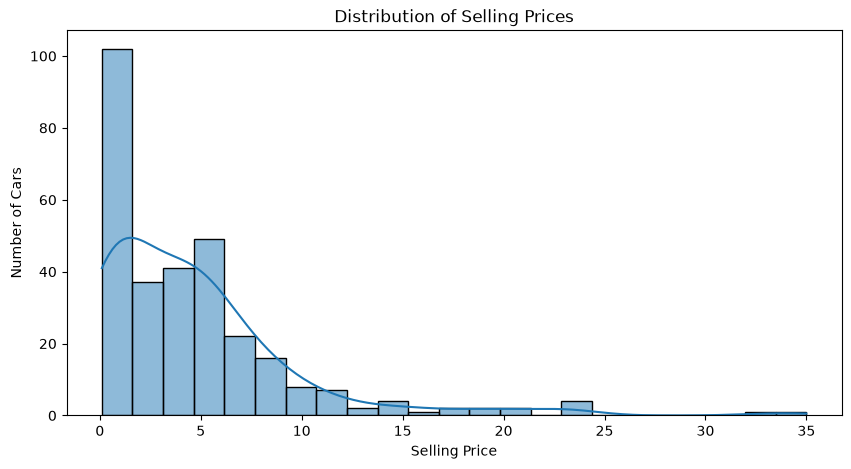

In [ ]:
# Plot distribution of selling prices

plt.figure(figsize=(10, 5))

sns.histplot(
    df["Selling_Price"],
    kde=True
)

plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

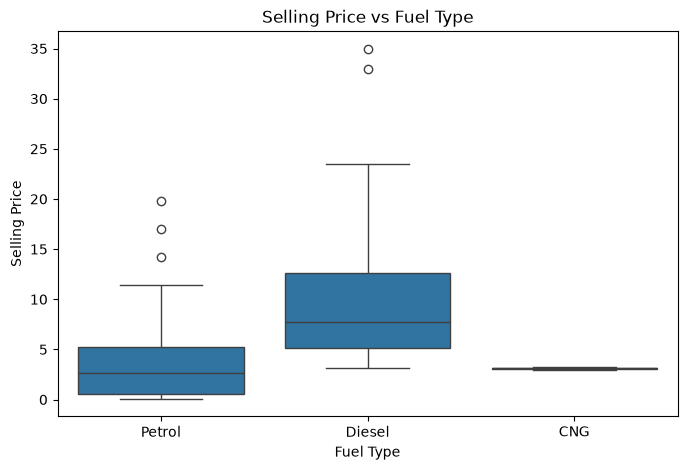

In [ ]:
# Box plot of selling price by fuel type

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Fuel_Type",
    y="Selling_Price",
    data=df
)

plt.title("Selling Price vs Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.show()

In [81]:
# Create Car Age

current_year = 2026
df["Car_Age"] = current_year - df["Year"]

print("Car_Age column created successfully.")
print(df[["Year", "Car_Age"]].head())

Car_Age column created successfully.
   Year  Car_Age
0  2014       12
1  2013       13
2  2017        9
3  2011       15
4  2014       12


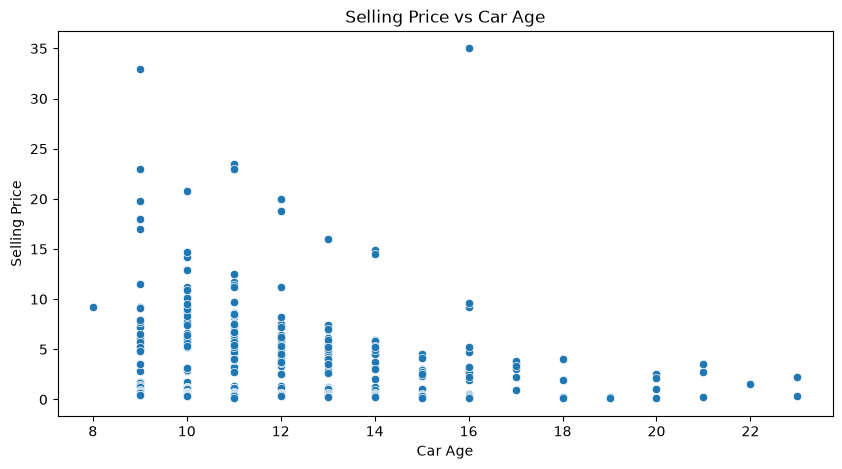

In [82]:
# Scatter plot of selling price vs car age

plt.figure(figsize=(10, 5))

sns.scatterplot(
    x="Car_Age",
    y="Selling_Price",
    data=df
)

plt.title("Selling Price vs Car Age")
plt.xlabel("Car Age")
plt.ylabel("Selling Price")

plt.show()

### Feature Correlation Heatmap

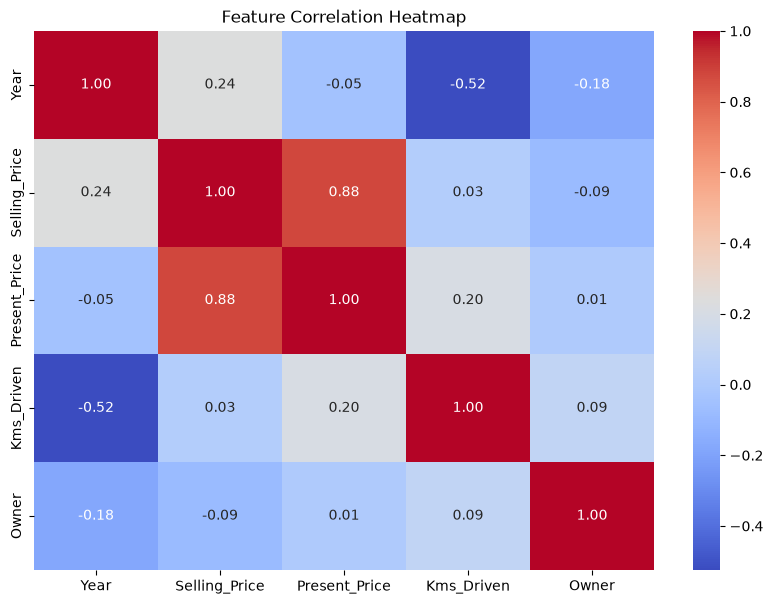

In [ ]:
# Select numerical columns

numeric_data = df.select_dtypes(include=np.number)

# Calculate correlations

correlation_matrix = numeric_data.corr()

# Create heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
# Separate features and target

X = df.drop(
    columns=["Selling_Price", "Car_Name", "Year"]
)

y = df["Selling_Price"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Selling_Price")

Features:
['Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Target:
Selling_Price


In [ ]:
# Identify categorical features

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify numerical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['Fuel_Type', 'Seller_Type', 'Transmission']

Numerical features:
['Present_Price', 'Kms_Driven', 'Owner']


In [ ]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 240
Testing samples: 61


In [ ]:
# Create Linear Regression pipeline

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model

linear_model.fit(X_train, y_train)

# Make predictions

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Calculate Linear Regression metrics

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R² Score:", linear_r2)

Linear Regression
-------------------------
MAE : 1.4490283806455204
RMSE: 2.248397614258532
R² Score: 0.780544234623148


In [ ]:
# Create Random Forest Regression pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42
            )
        )
    ]
    )

# Train the model

random_forest_model.fit(X_train, y_train)

# Make predictions

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Calculate Random Forest metrics

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest Regression")
print("-------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Regression
-------------------------
MAE : 0.8970872170179544
RMSE: 1.3710758832360934
R² Score: 0.9183936888627323


In [ ]:
# Create model comparison table

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    
    "MAE": [
        linear_mae,
        rf_mae
    ],
    
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    
    "R2 Score": [
        linear_r2,
        rf_r2
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.449028,2.248398,0.780544
1,Random Forest,0.897087,1.371076,0.918394


In [ ]:
# Sort models by R² score

results.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,RMSE,R2 Score
1,Random Forest,0.897087,1.371076,0.918394
0,Linear Regression,1.449028,2.248398,0.780544


In [ ]:
# Extract the trained Random Forest model

rf_model = random_forest_model.named_steps["model"]

# Get encoded categorical feature names

encoded_features = (
    random_forest_model
    .named_steps["preprocessor"]
    .named_transformers_["categorical"]
    .get_feature_names_out(categorical_features)
)

# Combine encoded and numerical feature names

feature_names = np.concatenate([
    encoded_features,
    numerical_features
])

# Get feature importance

importance = rf_model.feature_importances_

# Create DataFrame

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
7,Present_Price,0.889774
8,Kms_Driven,0.082814
6,Transmission_Manual,0.006924
1,Fuel_Type_Diesel,0.005849
5,Transmission_Automatic,0.005785
2,Fuel_Type_Petrol,0.004488
4,Seller_Type_Individual,0.001911
9,Owner,0.001255
3,Seller_Type_Dealer,0.001098
0,Fuel_Type_CNG,0.000101


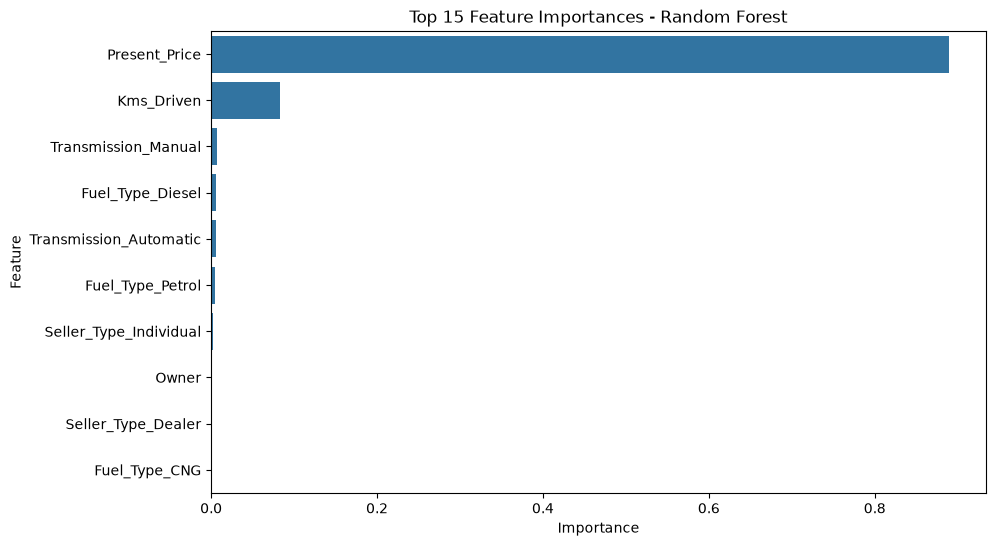

In [ ]:
# Plot top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=top_features
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

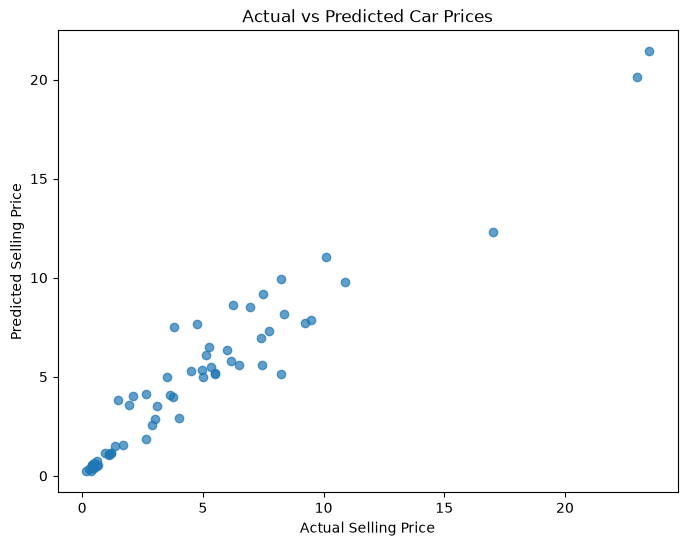

In [ ]:
# Plot actual vs predicted selling prices

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.7
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

In [ ]:
# Create data for a new car

new_car = pd.DataFrame({
    "Present_Price": [5.5],
    "Kms_Driven": [30000],
    "Fuel_Type": ["Petrol"],
    "Selling_type": ["Dealer"],
    "Transmission": ["Manual"],
    "Owner": [0],
    "Car_Age": [5],
    "Brand": ["ritz"]
})

# Predict selling price

predicted_price = random_forest_model.predict(new_car)

print(
    "Predicted Selling Price:",
    predicted_price[0]
)

ValueError: columns are missing: {'Seller_Type'}

# Conclusion

In this project, a machine learning regression system was developed to predict the selling price of used cars.

The dataset was cleaned by handling missing values, removing duplicate records, and standardizing categorical values. Feature engineering was performed by calculating car age from the year of manufacture and extracting a brand-related feature from the car name.

Exploratory Data Analysis was performed using selling price distribution, fuel type box plots, car age versus selling price scatter plots, and a correlation heatmap.

Two regression algorithms, Linear Regression and Random Forest Regression, were trained and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

The models were compared to determine the better-performing model. Feature importance was also analyzed using the Random Forest model to identify the features that contributed most to price prediction.

Overall, the project demonstrates how machine learning can be applied to estimate the selling price of used cars based on their characteristics.